| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

# Tugas: Filtering Citra Berbasis Domain Frekuensi
Deskripsi Tugas
Cari beberapa jenis citra digital dengan karakteristik berbeda. Lakukan filtering menggunakan pendekatan domain frekuensi berbasis 2D FFT, kemudian lakukan analisis terhadap pengaruh setiap filter terhadap karakteristik citra.



## I. Frequency Domain Filtering
Implementasikan metode:

- Low-Pass Filter (LPF)
- High-Pass Filter (HPF)

Untuk setiap filter, variasikan nilai cutoff radius (D0) dan tunjukkan perbandingan hasil antar nilai D0.

## II. Dataset
Gunakan 3 citra digital, masing-masing mewakili satu karakteristik berikut:
- Citra 1 — Citra dengan tekstur halus
- Citra 2 — Citra dengan tepi/objek yang tajam
- Citra 3 — Citra dengan noise periodik

## III. Implementasi

Untuk setiap citra:
1. Input dan Preprocessing

- Load image
- Grayscale conversion

2. Visualisasi Spectrum

- Terapkan 2D FFT
- Tampilkan magnitude spectrum

3. Low-Pass Filter (LPF)

- Terapkan LPF dengan minimal 3 nilai D0 berbeda
- Tampilkan hasil rekonstruksi citra untuk setiap D0

4. High-Pass Filter (HPF)

- Terapkan HPF dengan minimal 3 nilai D0 berbeda
- Tampilkan hasil rekonstruksi citra untuk setiap D0

## IV. Analisis
Berikan analisis mengenai:
- Pada nilai D0 berapa detail citra mulai hilang (LPF) atau noise mulai muncul (HPF)?
- Rentang D0 yang paling optimal untuk masing-masing karakteristik citra
- Kesesuaian metode filter terhadap karakteristik citra

## Format Pengumpulan
Kumpulkan dalam satu folder ZIP dengan nama NRP_Nama_Filtering.zip, berisi:
- NRP_Nama_Filtering.ipynb (sudah dijalankan / semua output tersedia)
- File citra yang digunakan

## Citra 1

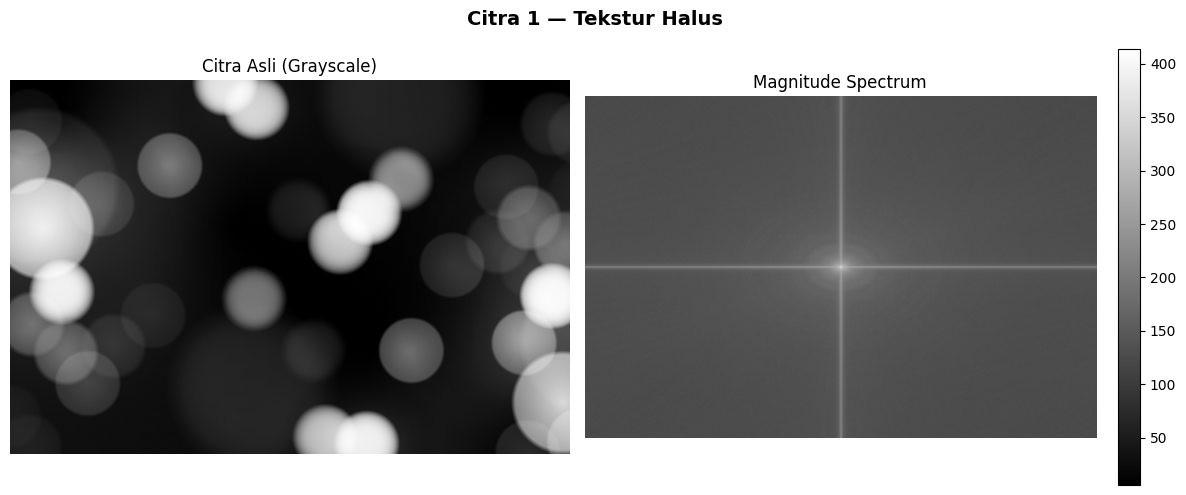

Ukuran citra: 3334 x 5000 piksel


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Image & Grayscale
img = cv2.imread('Defocused-Light.jpg', 0)
rows, cols = img.shape

# 2. FFT & Magnitude Spectrum
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)

# 3. Visualisasi dengan colorbar
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Citra 1 — Tekstur Halus', fontsize=14, fontweight='bold')

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Citra Asli (Grayscale)')
axes[0].axis('off')

im = axes[1].imshow(magnitude_spectrum, cmap='gray')
axes[1].set_title('Magnitude Spectrum')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

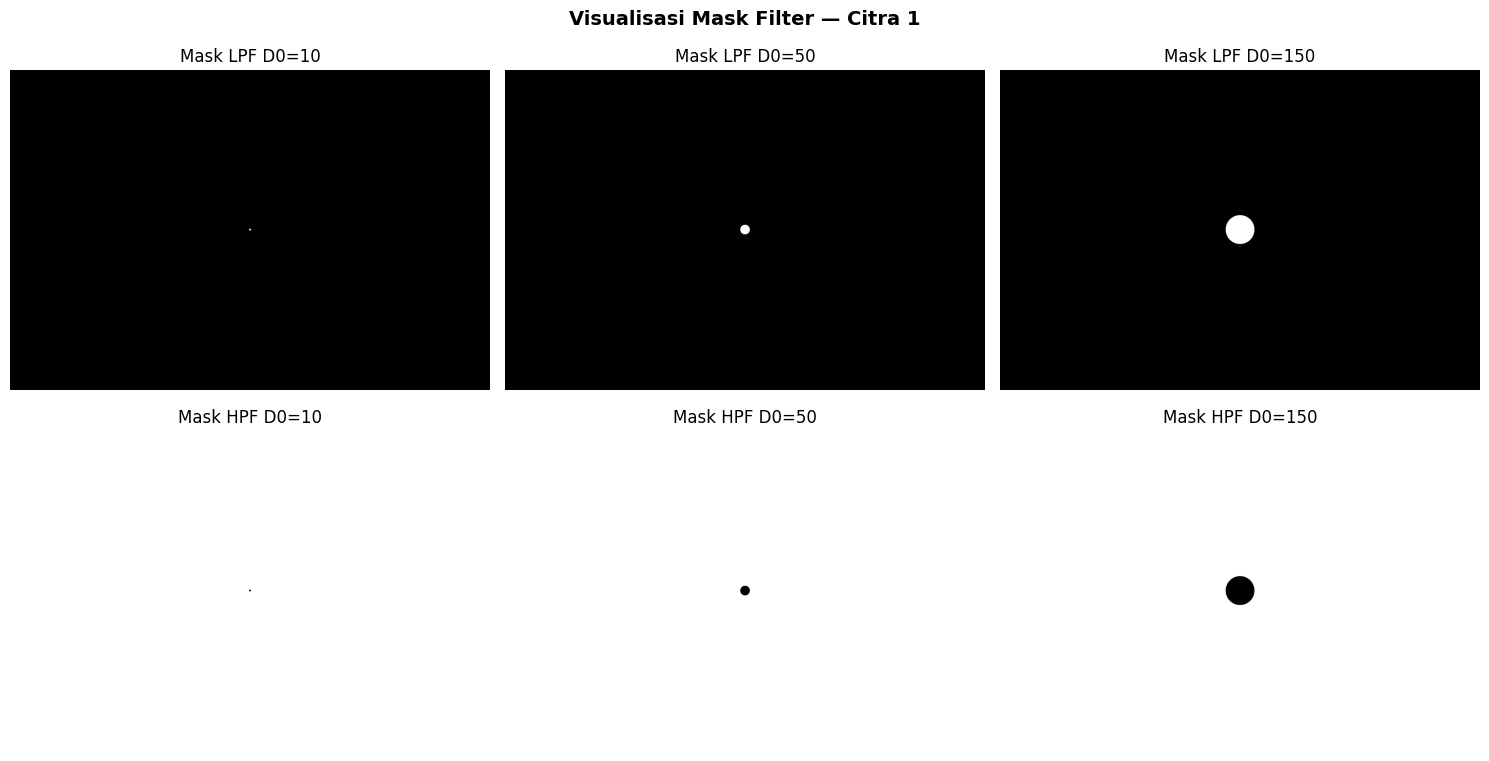

In [32]:
crow, ccol = rows // 2, cols // 2

u = np.arange(rows)
v = np.arange(cols)
U, V = np.meshgrid(v, u)
D = np.sqrt((U - ccol)**2 + (V - crow)**2)

# Visualisasi mask LPF dan HPF untuk setiap D0
D0_values = [10, 50, 150]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Visualisasi Mask Filter — Citra 1', fontsize=14, fontweight='bold')

for i, D0 in enumerate(D0_values):
    mask_lpf = (D <= D0).astype(np.uint8)
    mask_hpf = (D > D0).astype(np.uint8)

    axes[0, i].imshow(mask_lpf, cmap='gray')
    axes[0, i].set_title(f'Mask LPF D0={D0}')
    axes[0, i].axis('off')

    axes[1, i].imshow(mask_hpf, cmap='gray')
    axes[1, i].set_title(f'Mask HPF D0={D0}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

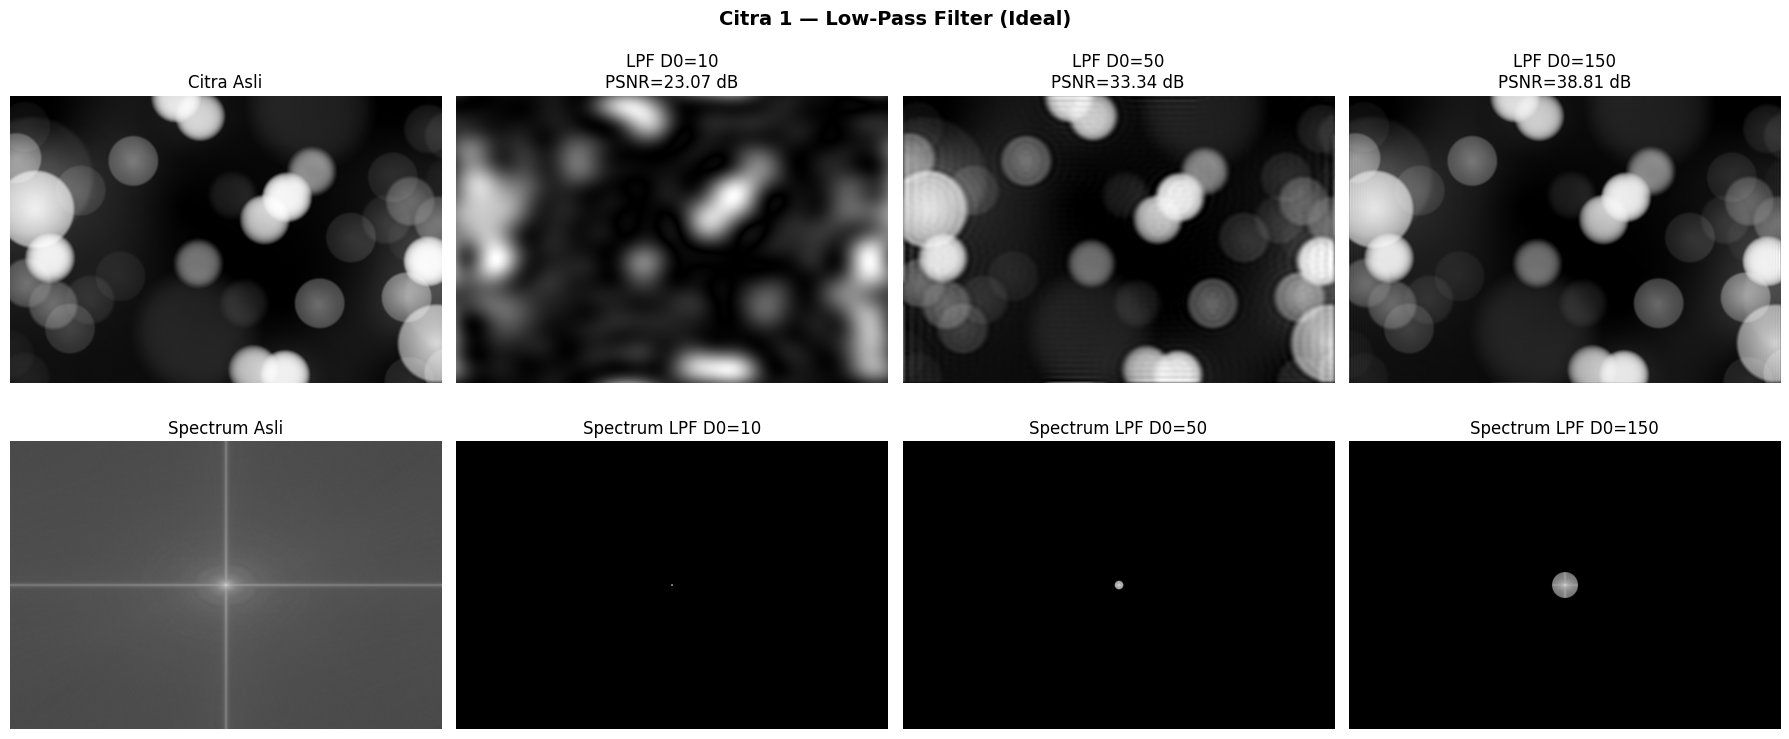

In [33]:
def psnr(original, filtered):
    mse = np.mean((original.astype(np.float64) - filtered) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

D0_values = [10, 50, 150]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Citra 1 — Low-Pass Filter (Ideal)', fontsize=14, fontweight='bold')

# Kolom pertama: citra asli
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Citra Asli')
axes[0, 0].axis('off')
axes[1, 0].imshow(magnitude_spectrum, cmap='gray')
axes[1, 0].set_title('Spectrum Asli')
axes[1, 0].axis('off')

for i, D0 in enumerate(D0_values):
    mask_lpf = np.zeros((rows, cols), np.uint8)
    mask_lpf[D <= D0] = 1

    fshift_filtered = fshift * mask_lpf
    f_ishift = np.fft.ifftshift(fshift_filtered)
    img_back = np.abs(np.fft.ifft2(f_ishift))

    mag_filtered = 20 * np.log(np.abs(fshift_filtered) + 1)
    psnr_val = psnr(img, img_back)

    axes[0, i+1].imshow(img_back, cmap='gray')
    axes[0, i+1].set_title(f'LPF D0={D0}\nPSNR={psnr_val:.2f} dB')
    axes[0, i+1].axis('off')

    axes[1, i+1].imshow(mag_filtered, cmap='gray')
    axes[1, i+1].set_title(f'Spectrum LPF D0={D0}')
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.show()

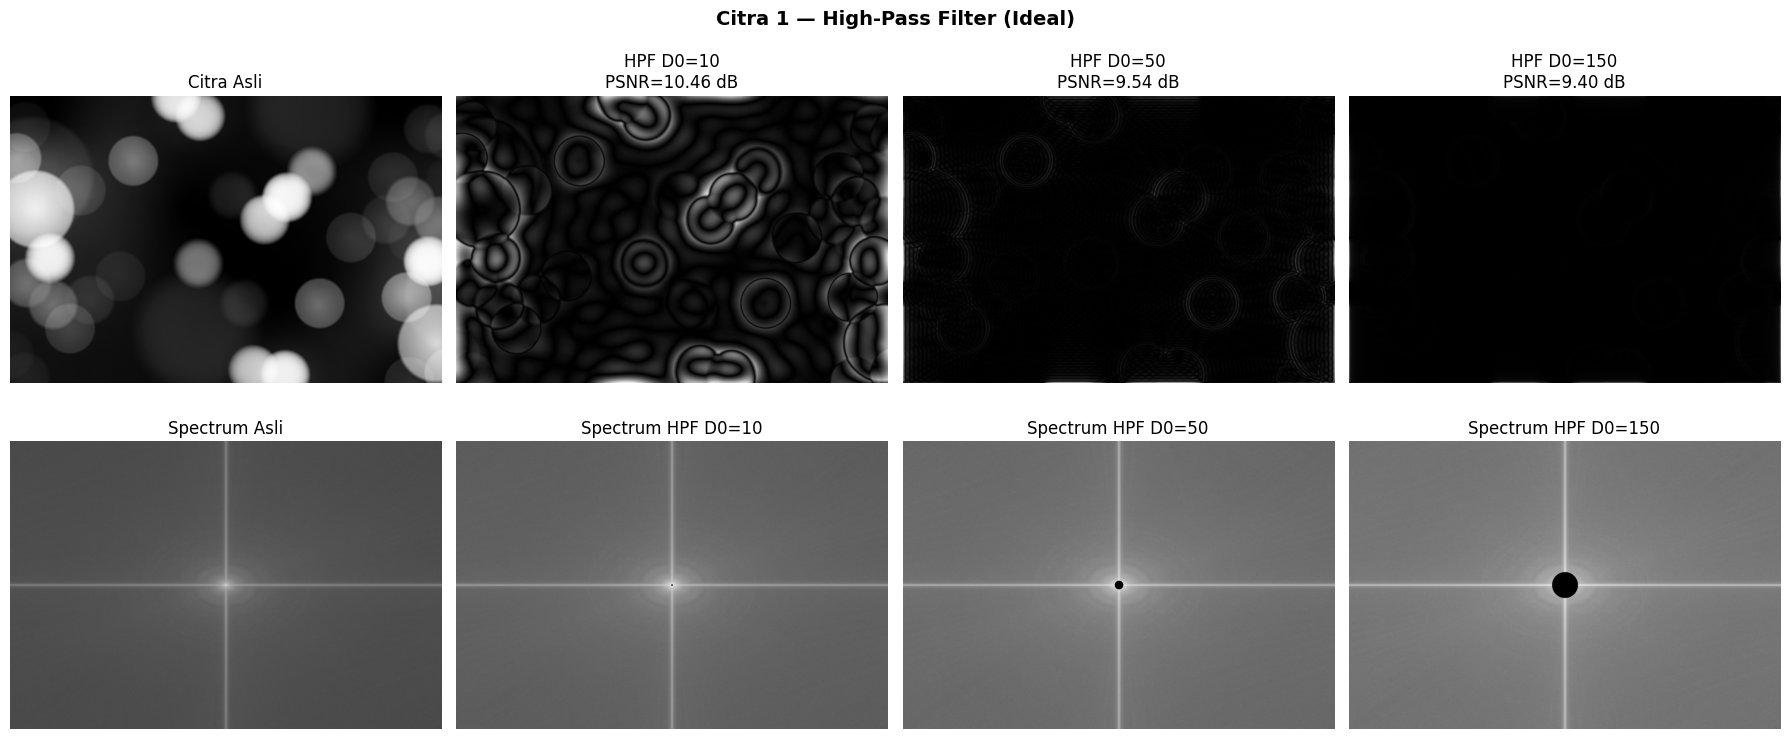

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Citra 1 — High-Pass Filter (Ideal)', fontsize=14, fontweight='bold')

axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Citra Asli')
axes[0, 0].axis('off')
axes[1, 0].imshow(magnitude_spectrum, cmap='gray')
axes[1, 0].set_title('Spectrum Asli')
axes[1, 0].axis('off')

for i, D0 in enumerate(D0_values):
    mask_hpf = np.ones((rows, cols), np.uint8)
    mask_hpf[D <= D0] = 0

    fshift_filtered_hpf = fshift * mask_hpf
    f_ishift_hpf = np.fft.ifftshift(fshift_filtered_hpf)
    img_back_hpf = np.abs(np.fft.ifft2(f_ishift_hpf))

    mag_filtered_hpf = 20 * np.log(np.abs(fshift_filtered_hpf) + 1)
    psnr_val = psnr(img, img_back_hpf)

    axes[0, i+1].imshow(img_back_hpf, cmap='gray')
    axes[0, i+1].set_title(f'HPF D0={D0}\nPSNR={psnr_val:.2f} dB')
    axes[0, i+1].axis('off')

    axes[1, i+1].imshow(mag_filtered_hpf, cmap='gray')
    axes[1, i+1].set_title(f'Spectrum HPF D0={D0}')
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.show()

## Citra 2

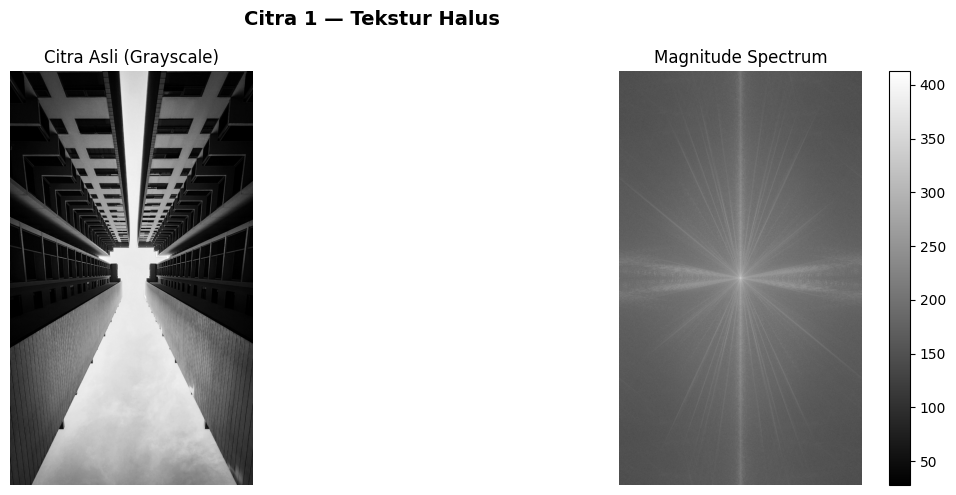

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Image & Grayscale
img = cv2.imread('High-Contrast-Architecture.jpg', 0)
rows, cols = img.shape

# 2. FFT & Magnitude Spectrum
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)

# 3. Visualisasi dengan colorbar
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Citra 1 — Tekstur Halus', fontsize=14, fontweight='bold')

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Citra Asli (Grayscale)')
axes[0].axis('off')

im = axes[1].imshow(magnitude_spectrum, cmap='gray')
axes[1].set_title('Magnitude Spectrum')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

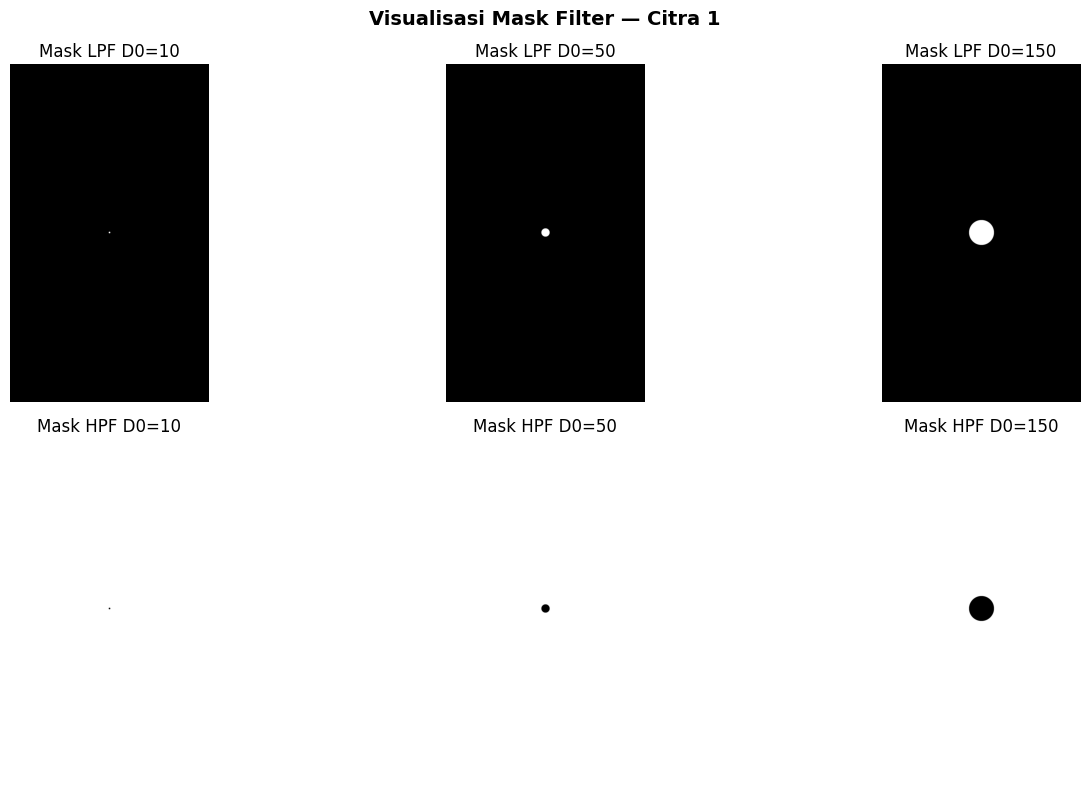

In [36]:
crow, ccol = rows // 2, cols // 2

u = np.arange(rows)
v = np.arange(cols)
U, V = np.meshgrid(v, u)
D = np.sqrt((U - ccol)**2 + (V - crow)**2)

# Visualisasi mask LPF dan HPF untuk setiap D0
D0_values = [10, 50, 150]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Visualisasi Mask Filter — Citra 1', fontsize=14, fontweight='bold')

for i, D0 in enumerate(D0_values):
    mask_lpf = (D <= D0).astype(np.uint8)
    mask_hpf = (D > D0).astype(np.uint8)

    axes[0, i].imshow(mask_lpf, cmap='gray')
    axes[0, i].set_title(f'Mask LPF D0={D0}')
    axes[0, i].axis('off')

    axes[1, i].imshow(mask_hpf, cmap='gray')
    axes[1, i].set_title(f'Mask HPF D0={D0}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

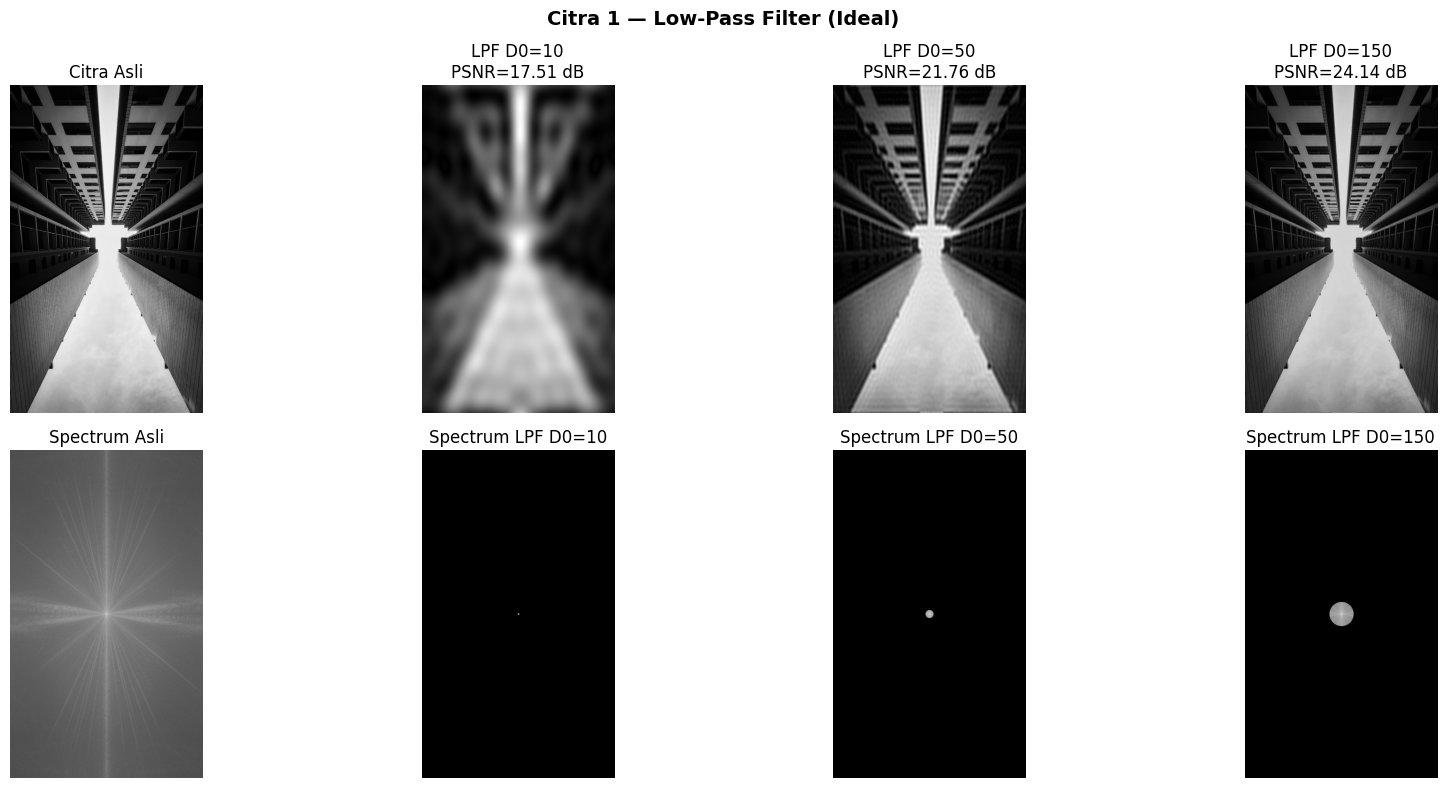

In [38]:
def psnr(original, filtered):
    mse = np.mean((original.astype(np.float64) - filtered) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

D0_values = [10, 50, 150]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Citra 1 — Low-Pass Filter (Ideal)', fontsize=14, fontweight='bold')

# Kolom pertama: citra asli
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Citra Asli')
axes[0, 0].axis('off')
axes[1, 0].imshow(magnitude_spectrum, cmap='gray')
axes[1, 0].set_title('Spectrum Asli')
axes[1, 0].axis('off')

for i, D0 in enumerate(D0_values):
    mask_lpf = np.zeros((rows, cols), np.uint8)
    mask_lpf[D <= D0] = 1

    fshift_filtered = fshift * mask_lpf
    f_ishift = np.fft.ifftshift(fshift_filtered)
    img_back = np.abs(np.fft.ifft2(f_ishift))

    mag_filtered = 20 * np.log(np.abs(fshift_filtered) + 1)
    psnr_val = psnr(img, img_back)

    axes[0, i+1].imshow(img_back, cmap='gray')
    axes[0, i+1].set_title(f'LPF D0={D0}\nPSNR={psnr_val:.2f} dB')
    axes[0, i+1].axis('off')

    axes[1, i+1].imshow(mag_filtered, cmap='gray')
    axes[1, i+1].set_title(f'Spectrum LPF D0={D0}')
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.show()

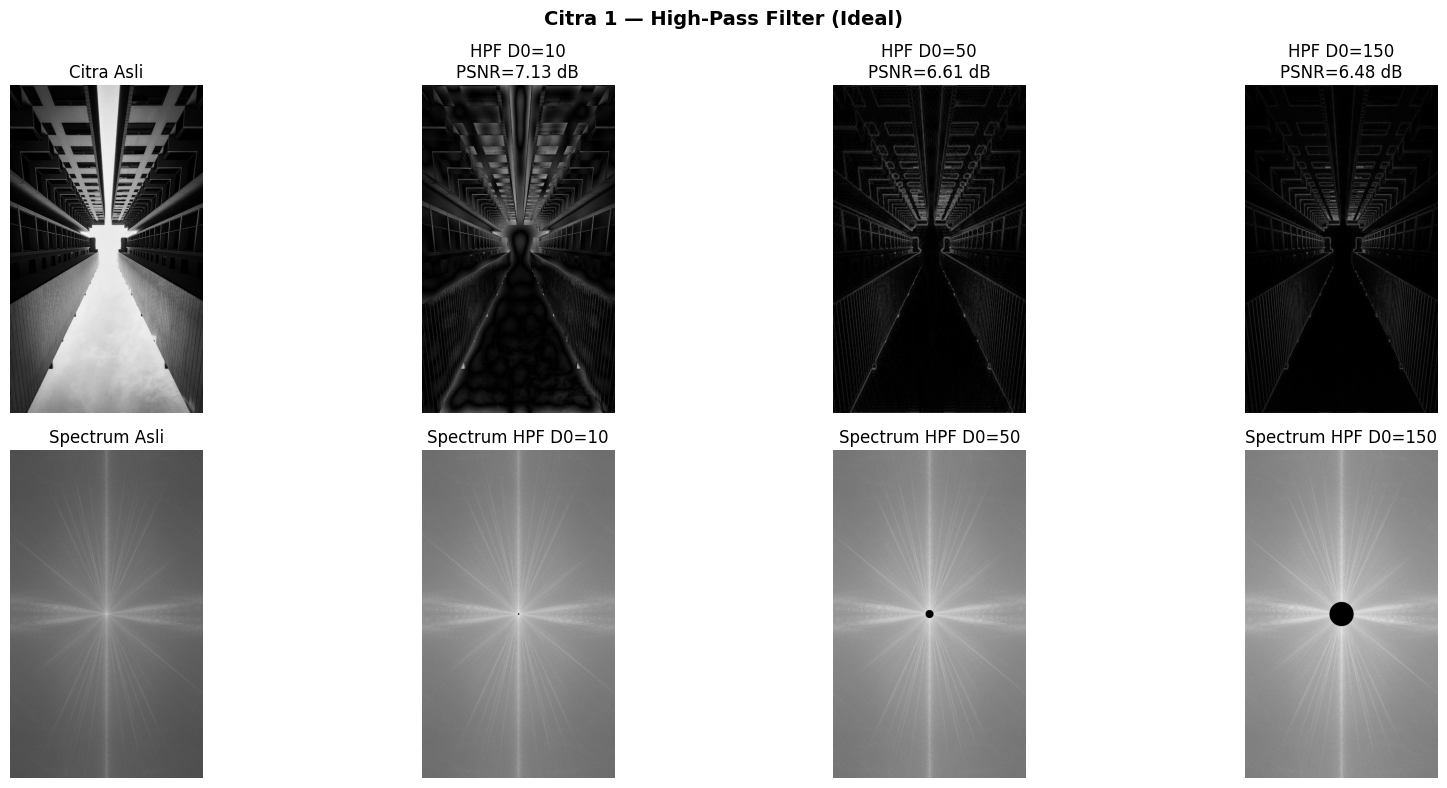

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Citra 1 — High-Pass Filter (Ideal)', fontsize=14, fontweight='bold')

axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Citra Asli')
axes[0, 0].axis('off')
axes[1, 0].imshow(magnitude_spectrum, cmap='gray')
axes[1, 0].set_title('Spectrum Asli')
axes[1, 0].axis('off')

for i, D0 in enumerate(D0_values):
    mask_hpf = np.ones((rows, cols), np.uint8)
    mask_hpf[D <= D0] = 0

    fshift_filtered_hpf = fshift * mask_hpf
    f_ishift_hpf = np.fft.ifftshift(fshift_filtered_hpf)
    img_back_hpf = np.abs(np.fft.ifft2(f_ishift_hpf))

    mag_filtered_hpf = 20 * np.log(np.abs(fshift_filtered_hpf) + 1)
    psnr_val = psnr(img, img_back_hpf)

    axes[0, i+1].imshow(img_back_hpf, cmap='gray')
    axes[0, i+1].set_title(f'HPF D0={D0}\nPSNR={psnr_val:.2f} dB')
    axes[0, i+1].axis('off')

    axes[1, i+1].imshow(mag_filtered_hpf, cmap='gray')
    axes[1, i+1].set_title(f'Spectrum HPF D0={D0}')
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.show()

## Citra 3

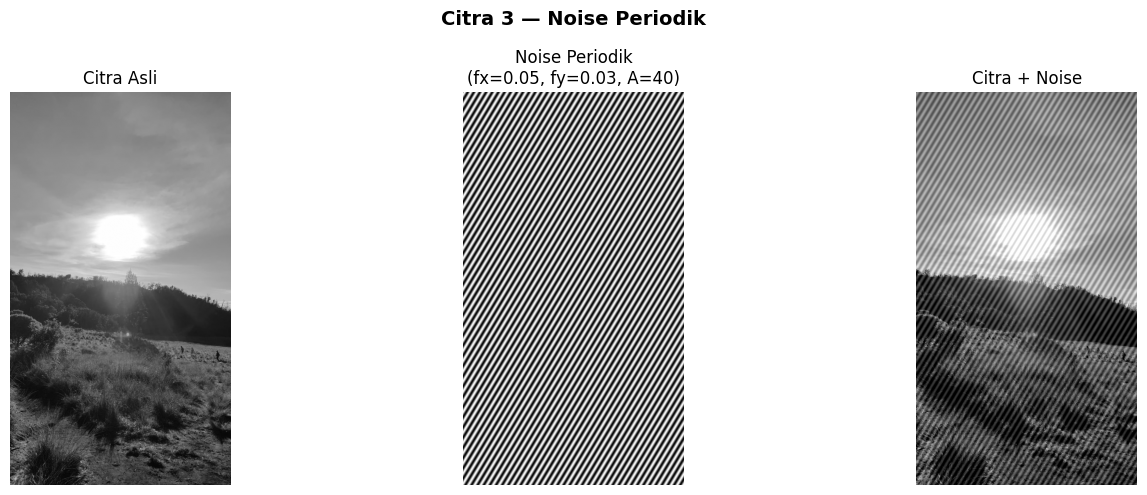

In [40]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Image & Grayscale
img_original = cv2.imread('Noise-Periodic.jpeg', 0)
rows, cols = img_original.shape

# 2. Buat noise periodik sinusoidal
x = np.arange(cols)
y = np.arange(rows)
X, Y = np.meshgrid(x, y)

fx, fy = 0.05, 0.03
amplitude = 40
noise = amplitude * np.sin(2 * np.pi * fx * X + 2 * np.pi * fy * Y)

# 3. Tambahkan noise ke citra asli
img_noisy = np.clip(img_original.astype(np.float64) + noise, 0, 255).astype(np.uint8)

# 4. Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Citra 3 — Noise Periodik', fontsize=14, fontweight='bold')

axes[0].imshow(img_original, cmap='gray')
axes[0].set_title('Citra Asli')
axes[0].axis('off')

axes[1].imshow(noise, cmap='gray')
axes[1].set_title(f'Noise Periodik\n(fx={fx}, fy={fy}, A={amplitude})')
axes[1].axis('off')

axes[2].imshow(img_noisy, cmap='gray')
axes[2].set_title('Citra + Noise')
axes[2].axis('off')

plt.tight_layout()
plt.show()

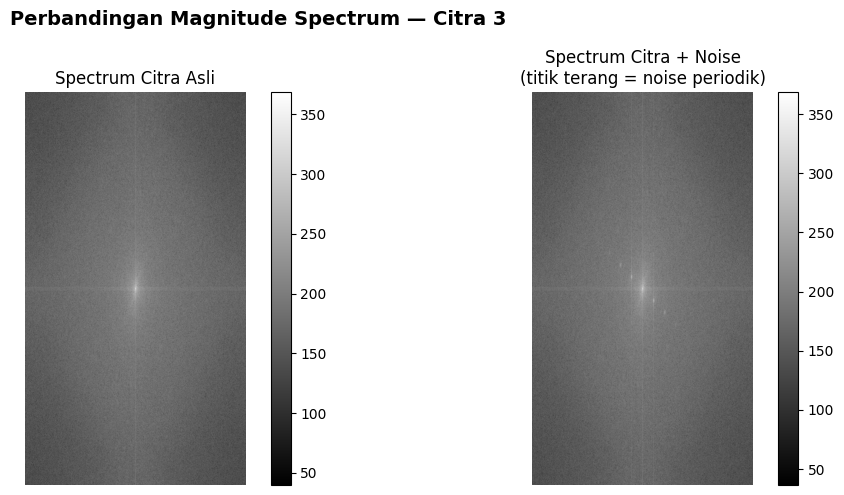

In [41]:
# FFT citra asli
f_original = np.fft.fft2(img_original)
fshift_original = np.fft.fftshift(f_original)
mag_original = 20 * np.log(np.abs(fshift_original) + 1)

# FFT citra noisy
f = np.fft.fft2(img_noisy)
fshift = np.fft.fftshift(f)
mag_noisy = 20 * np.log(np.abs(fshift) + 1)

# Visualisasi perbandingan spectrum
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Perbandingan Magnitude Spectrum — Citra 3', fontsize=14, fontweight='bold')

im0 = axes[0].imshow(mag_original, cmap='gray')
axes[0].set_title('Spectrum Citra Asli')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(mag_noisy, cmap='gray')
axes[1].set_title('Spectrum Citra + Noise\n(titik terang = noise periodik)')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

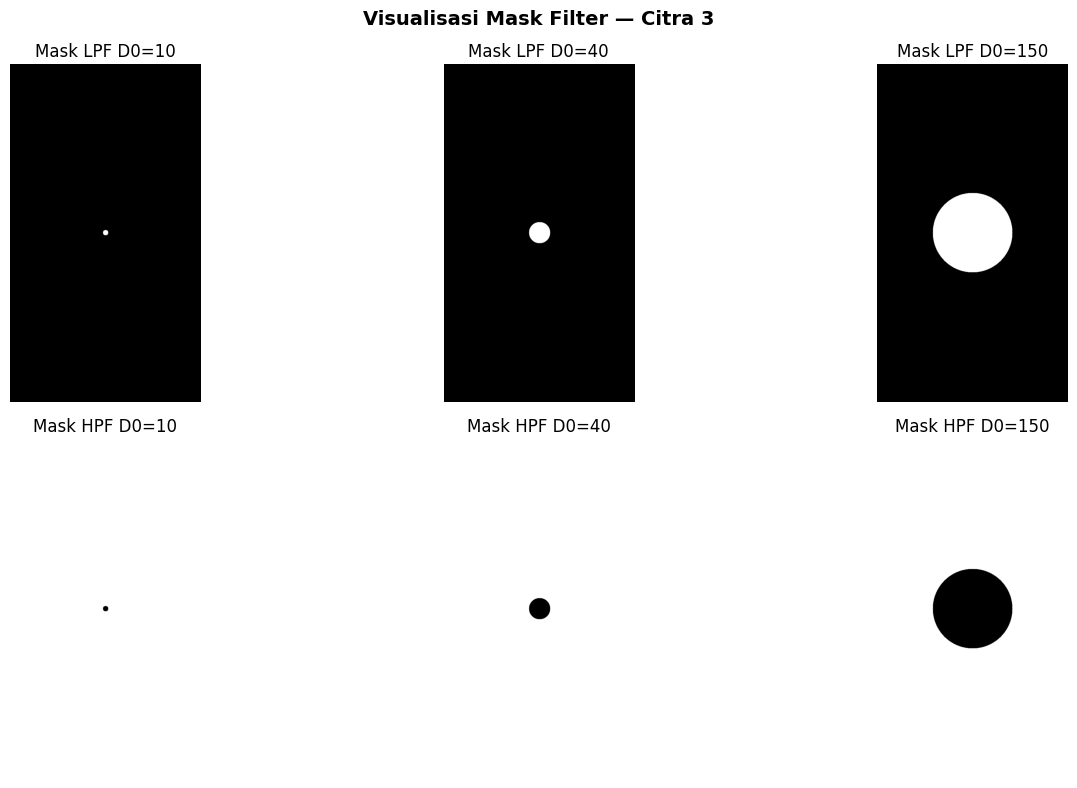

: 

In [ ]:
crow, ccol = rows // 2, cols // 2

u = np.arange(rows)
v = np.arange(cols)
U, V = np.meshgrid(v, u)
D = np.sqrt((U - ccol)**2 + (V - crow)**2)

D0_values = [10, 40, 150]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Visualisasi Mask Filter — Citra 3', fontsize=14, fontweight='bold')

for i, D0 in enumerate(D0_values):
    mask_lpf = (D <= D0).astype(np.uint8)
    mask_hpf = (D > D0).astype(np.uint8)

    axes[0, i].imshow(mask_lpf, cmap='gray')
    axes[0, i].set_title(f'Mask LPF D0={D0}')
    axes[0, i].axis('off')

    axes[1, i].imshow(mask_hpf, cmap='gray')
    axes[1, i].set_title(f'Mask HPF D0={D0}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

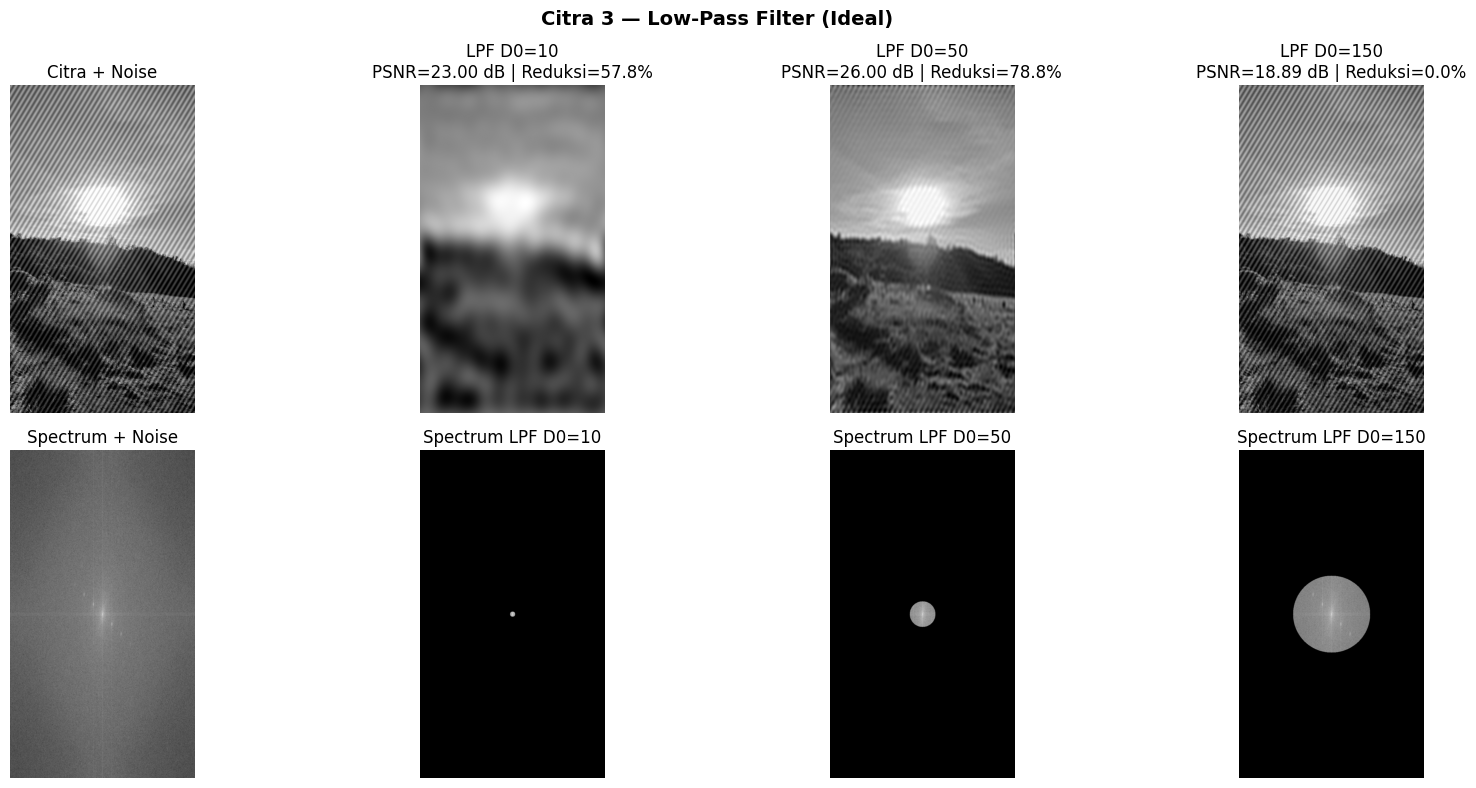

In [49]:
def psnr(original, filtered):
    mse = np.mean((original.astype(np.float64) - filtered) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

def noise_reduction_percent(img_noisy, img_original, img_filtered):
    noise_before = np.mean((img_noisy.astype(np.float64) - img_original.astype(np.float64)) ** 2)
    noise_after = np.mean((img_filtered - img_original.astype(np.float64)) ** 2)
    return max(0, (1 - noise_after / noise_before) * 100)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Citra 3 — Low-Pass Filter (Ideal)', fontsize=14, fontweight='bold')

axes[0, 0].imshow(img_noisy, cmap='gray')
axes[0, 0].set_title('Citra + Noise')
axes[0, 0].axis('off')
axes[1, 0].imshow(mag_noisy, cmap='gray')
axes[1, 0].set_title('Spectrum + Noise')
axes[1, 0].axis('off')

for i, D0 in enumerate(D0_values):
    mask_lpf = np.zeros((rows, cols), np.uint8)
    mask_lpf[D <= D0] = 1

    fshift_filtered = fshift * mask_lpf
    f_ishift = np.fft.ifftshift(fshift_filtered)
    img_back = np.abs(np.fft.ifft2(f_ishift))

    mag_filtered = 20 * np.log(np.abs(fshift_filtered) + 1)
    psnr_val = psnr(img_original, img_back)
    noise_red = noise_reduction_percent(img_noisy, img_original, img_back)

    axes[0, i+1].imshow(img_back, cmap='gray')
    axes[0, i+1].set_title(f'LPF D0={D0}\nPSNR={psnr_val:.2f} dB | Reduksi={noise_red:.1f}%')
    axes[0, i+1].axis('off')

    axes[1, i+1].imshow(mag_filtered, cmap='gray')
    axes[1, i+1].set_title(f'Spectrum LPF D0={D0}')
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.show()

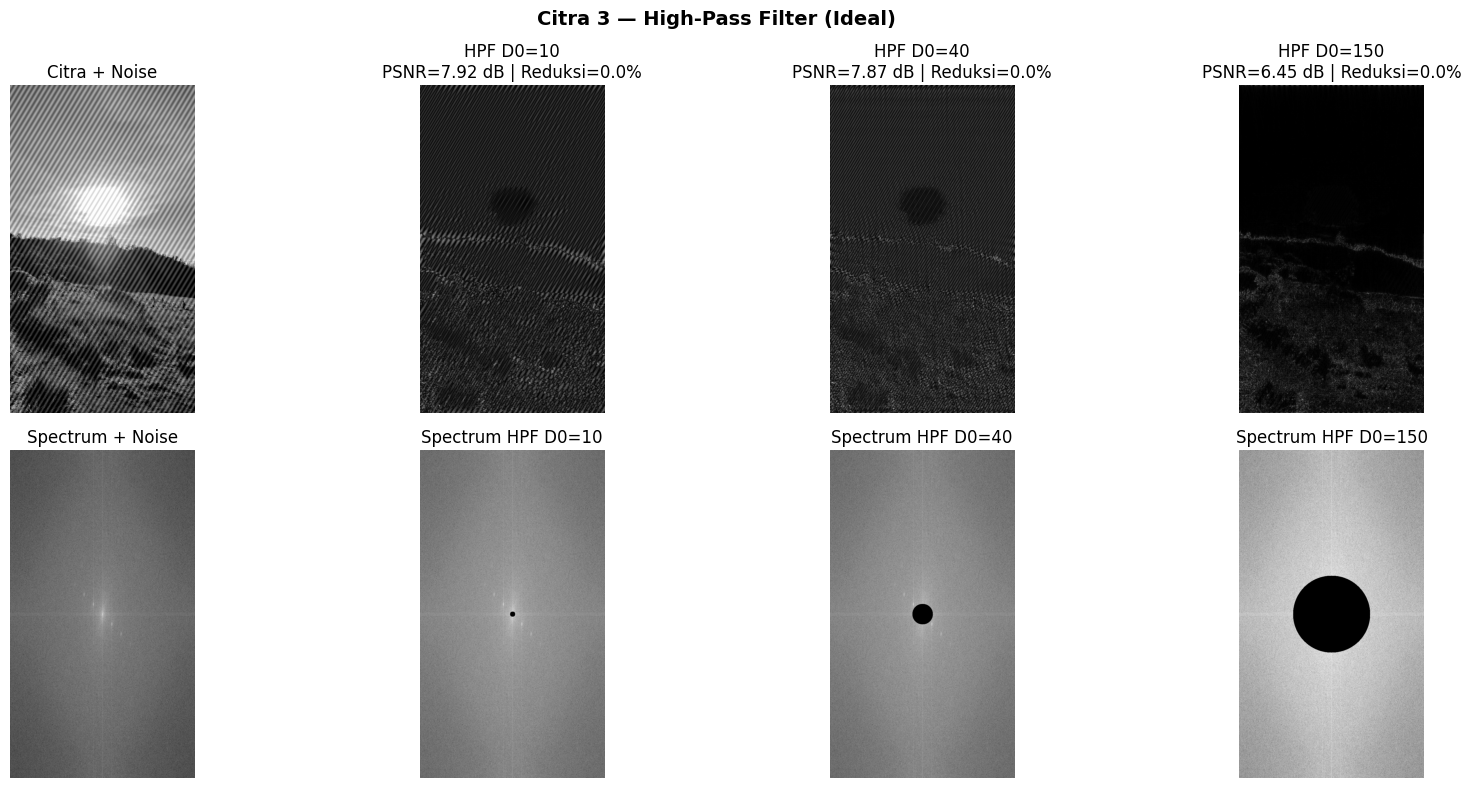

In [47]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Citra 3 — High-Pass Filter (Ideal)', fontsize=14, fontweight='bold')

axes[0, 0].imshow(img_noisy, cmap='gray')
axes[0, 0].set_title('Citra + Noise')
axes[0, 0].axis('off')
axes[1, 0].imshow(mag_noisy, cmap='gray')
axes[1, 0].set_title('Spectrum + Noise')
axes[1, 0].axis('off')

for i, D0 in enumerate(D0_values):
    mask_hpf = np.ones((rows, cols), np.uint8)
    mask_hpf[D <= D0] = 0

    fshift_filtered_hpf = fshift * mask_hpf
    f_ishift_hpf = np.fft.ifftshift(fshift_filtered_hpf)
    img_back_hpf = np.abs(np.fft.ifft2(f_ishift_hpf))

    mag_filtered_hpf = 20 * np.log(np.abs(fshift_filtered_hpf) + 1)
    psnr_val = psnr(img_original, img_back_hpf)
    noise_red = noise_reduction_percent(img_noisy, img_original, img_back_hpf)

    axes[0, i+1].imshow(img_back_hpf, cmap='gray')
    axes[0, i+1].set_title(f'HPF D0={D0}\nPSNR={psnr_val:.2f} dB | Reduksi={noise_red:.1f}%')
    axes[0, i+1].axis('off')

    axes[1, i+1].imshow(mag_filtered_hpf, cmap='gray')
    axes[1, i+1].set_title(f'Spectrum HPF D0={D0}')
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.show()

## Analisis Hasil Filtering Frekuensi Domain

---

### 1. Nilai D0 saat detail mulai hilang (LPF) / noise mulai muncul (HPF)

**LPF — detail mulai hilang:**
- Citra 1 (Tekstur Halus): Detail mulai hilang pada D0 < 50, sangat signifikan pada D0 = 10
- Citra 2 (Tepi Tajam): Detail tepi mulai hilang pada D0 < 100, hampir hilang total pada D0 = 10
- Citra 3 (Noise Periodik): Detail citra mulai blur pada D0 < 20, namun noise justru berhasil direduksi

**HPF — noise/artefak mulai muncul:**
- Citra 1 (Tekstur Halus): Artefak muncul pada D0 > 50, citra sangat terdegradasi pada D0 = 150
- Citra 2 (Tepi Tajam): Informasi non-tepi hilang pada D0 > 50, hanya sisa tepi dominan pada D0 = 150
- Citra 3 (Noise Periodik): Noise periodik semakin dominan pada semua nilai D0 karena HPF justru mempertahankan frekuensi tinggi tempat noise berada

---

### 2. Rentang D0 optimal untuk masing-masing karakteristik citra

- Citra 1 (Tekstur Halus): LPF D0 = 50–150 | HPF D0 = 10–20
- Citra 2 (Tepi Tajam): LPF D0 = 100–150 | HPF D0 = 10–30
- Citra 3 (Noise Periodik): LPF D0 = 20–50 (optimal reduksi noise) | HPF tidak direkomendasikan

---

### 3. Kesesuaian metode filter terhadap karakteristik citra

- Citra 1 (Tekstur Halus): **LPF lebih sesuai** — energi citra terkonsentrasi di frekuensi rendah sehingga LPF mempertahankan karakter halus citra dengan baik
- Citra 2 (Tepi Tajam): **HPF lebih sesuai** — HPF dengan D0 kecil mampu menonjolkan tepi dan garis struktural yang menjadi karakteristik utama citra arsitektur
- Citra 3 (Noise Periodik): **LPF lebih sesuai** — noise periodik berada di frekuensi tinggi sehingga LPF efektif mereduksinya, dibuktikan dengan nilai PSNR lebih tinggi dan persentase reduksi noise yang signifikan dibanding HPF